# 06a — Wasserstein NMF with the dual solver of Rolet, Cuturi & Peyré (2016)

Implements *Fast Dictionary Learning with a Smoothed Wasserstein Loss* (AISTATS 2016, [PMLR v51](https://proceedings.mlr.press/v51/rolet16.html)) on the same simulated catalogues as `05` and `06`. Paper notation: dictionary $D$ = signatures $W$, weights $\Lambda$ = exposures $H$.

**Problem** (paper, Problem 9, with columns of $D$ and $\Lambda$ on the simplex):

$$\min_{D,\Lambda}\; \sum_i \omega_i\, H_{a_i}(D\lambda_i) \;+\; \rho_1 \sum_i \langle \lambda_i, \log \lambda_i\rangle \;+\; \rho_2 \sum_k \langle d_k, \log d_k\rangle,$$

where $H_a(b) = W_\gamma(a, b) = \min_{T \in U(a,b)} \langle C, T\rangle - \gamma h(T)$ is the entropy-smoothed Wasserstein loss and $a_i = x_i / \lVert x_i\rVert_1$. The entropy terms act as positivity barriers that keep $D$ and $\Lambda$ inside the simplex (they pull towards higher entropy).

**Key idea: solve each block in the dual.** With $K = e^{-C/\gamma}$ and $\alpha = e^{g/\gamma}$, the Legendre conjugate of $H_a$ is explicit:

$$H_a^*(g) = \gamma\big(\langle a, \log K\alpha\rangle \pm E(a)\big), \qquad \nabla H_a^*(g) = \alpha \odot K^\top (a \oslash K\alpha).$$

*(The constant $E(a)$ only shifts objective values; with the sign convention above it enters with $-$, which the duality-gap check in §2 confirms.)*

- **Λ-step (Theorem 3).** With $D$ fixed, solve $\min_G \sum_i \omega_i H^*_{a_i}(g_i/\omega_i) + \rho_1 \sum_i \operatorname{lse}(-D^\top g_i/\rho_1)$, then recover $\lambda_i = \operatorname{softmax}(-D^\top g_i/\rho_1)$.
- **D-step (Theorem 4).** With $\Lambda$ fixed, solve $\min_G \sum_i \omega_i H^*_{a_i}(g_i/\omega_i) + \rho_2 \sum_k \operatorname{lse}(-(G\Lambda^\top)_k/\rho_2)$, then recover $d_k = \operatorname{softmax}(-(G\Lambda^\top)_k/\rho_2)$.

Both duals are smooth and unconstrained, and their gradients are simply $\nabla H^*(G) - D\Lambda$: the mismatch between the reconstruction and the transported data. Following the paper, they are solved with **Nesterov's accelerated gradient** with step $1/L$, where $L = 1/(\gamma\,\min_i \omega_i) + \lVert D\rVert_2^2/\rho_1$ (Λ-step) or $+\lVert \Lambda\rVert_2^2/\rho_2$ (D-step). The two steps alternate (block-coordinate descent).

**Choices the paper leaves open** (marked `# CHOICE` below): number of inner iterations, warm starts (the dual variables are warm-started across outer iterations), stopping, initialisation, and restarts. Two deliberate **extensions**:
1. Sample weights $\omega_i$ (the paper is unweighted); `"burden"` is the default, for the same reason as in `06`, and `"uniform"` recovers the paper exactly.
2. Restarts, keeping the solution with the lowest primal objective.

The paper does not use L-BFGS. I tried it on these data: it was about 35× slower and less accurate, so it is not included.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linear_sum_assignment
from scipy.special import logsumexp, softmax

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
DATA = ROOT / "data"
SIM = next((p for p in [ROOT / "simulated_data", DATA / "simulated_data"] if p.is_dir()), None)
assert SIM is not None, "simulated_data/ not found: run 02a_simulate_data_oldReport_method.ipynb first"
COST_DIR = DATA / "cost_matrix"
OUT = ROOT / "results" / "wnmf_dual"
OUT.mkdir(parents=True, exist_ok=True)

SUBS = ["C>A", "C>G", "C>T", "T>A", "T>C", "T>G"]
SUB_COLORS = dict(zip(SUBS, ["#1ebff0", "#050708", "#e62725", "#cbcacb", "#a1cf64", "#edc8c5"]))
BASES = ["A", "C", "G", "T"]
CHANNELS = pd.Index([f"{f}[{s}]{t}" for s in SUBS for f in BASES for t in BASES], name="MutationType")
SUB_OF = CHANNELS.str[2:5].to_numpy(dtype=str)

## 1. Parameters

In [2]:
N_SIGNATURES_LIST = [8, 15, 25]
NOISE_LEVELS = [0.02, 0.04, 0.06]
DETAIL = (15, 0.04)
DETAIL_COST = "graph_struct"
BENCH_COSTS = ["lin_hamming", "graph_struct"]

GAMMA = 0.02            # entropic smoothing of the Wasserstein loss (cost scaled to max 1); paper: 1/30-1/50 on its own scale
RHO1 = 0.01             # entropy barrier on the exposures Λ
RHO2 = 0.05             # entropy barrier on the signatures D; tuned in §4, the most influential parameter here
N_OUTER = 50            # CHOICE: block-coordinate iterations (Λ-step + D-step)
N_INNER = 100           # CHOICE: Nesterov iterations per dual subproblem (warm-started)
OUTER_TOL = 1e-4        # CHOICE: stop when the mean L1 change of the signature columns is below this
SAMPLE_WEIGHT = "burden"  # extension; "uniform" = the paper
N_RESTARTS = 3          # extension: random initialisations, lowest primal objective kept
SEED = 2025
COS_GOOD = 0.9

## 2. Solver

In [3]:
def tag(k, noise):
    return f"k{k}_noise{int(round(noise * 100))}pct"


def load(k, noise):
    t = tag(k, noise)
    X = pd.read_csv(SIM / f"X_{t}.csv", index_col=0)
    W = pd.read_csv(SIM / f"W_true_{t}.csv", index_col=0)
    H = pd.read_csv(SIM / f"H_true_{t}.csv", index_col=0)
    return X.loc[CHANNELS], W.loc[CHANNELS], H


def load_cost(name):
    return pd.read_csv(COST_DIR / f"C_{name}_scaled.csv", index_col=0).loc[CHANNELS, CHANNELS].values


def sample_weights(X, how=SAMPLE_WEIGHT):
    tot = np.asarray(X, float).sum(0)
    w = {"burden": tot, "sqrt": np.sqrt(tot), "uniform": np.ones_like(tot)}[how]
    return w / w.mean()


def hstar(G, A, K, gamma, w):
    # sum_i w_i H*_{a_i}(g_i / w_i) without the constant E(a) term, and its gradient (= grad H* at g_i / w_i)
    Gs = G / w
    gmax = Gs.max(0)
    alpha = np.exp((Gs - gmax) / gamma)          # stabilised alpha = e^{g/gamma}
    Ka = K @ alpha
    val = gamma * np.sum(w * np.sum(A * (np.log(Ka) + gmax / gamma), 0))
    grad = alpha * (K.T @ (A / Ka))
    return val, grad


def lambda_dual(G, A, K, gamma, w, D, rho1):
    # Theorem 3: dual objective of the Λ-step, gradient, and primal recovery
    v, Y = hstar(G, A, K, gamma, w)
    Z = -D.T @ G / rho1
    Lam = softmax(Z, axis=0)
    return v + rho1 * logsumexp(Z, axis=0).sum(), Y - D @ Lam, Lam


def dict_dual(G, A, K, gamma, w, Lam, rho2):
    # Theorem 4: dual objective of the D-step, gradient, and primal recovery
    v, Y = hstar(G, A, K, gamma, w)
    Z = -G @ Lam.T / rho2
    D = softmax(Z, axis=0)
    return v + rho2 * logsumexp(Z, axis=0).sum(), Y - D @ Lam, D


def nesterov(fun, G0, L, n_iter):
    # accelerated gradient (Nesterov, 1983) with constant step 1/L, as in the paper
    G = G0.copy(); Y = G0.copy(); t = 1.0
    for _ in range(n_iter):
        _, g, _ = fun(Y)
        G_new = Y - g / L
        t_new = (1 + np.sqrt(1 + 4 * t * t)) / 2
        Y = G_new + (t - 1) / t_new * (G_new - G)
        G, t = G_new, t_new
    f, g, primal = fun(G)
    return G, primal, f


def dual_wnmf(X, C, K_sig, gamma=GAMMA, rho1=RHO1, rho2=RHO2, n_outer=N_OUTER, n_inner=N_INNER, tol=OUTER_TOL,
              weights=SAMPLE_WEIGHT, rng=None, D0=None):
    X = np.asarray(X, float)
    A = X / X.sum(0)
    n, m = A.shape
    w = sample_weights(X, weights)
    K = np.exp(-C / gamma)
    rng = np.random.default_rng(rng)
    D = (rng.random((n, K_sig)) + 0.1) if D0 is None else np.asarray(D0, float).copy()
    D /= D.sum(0)
    G_lam = np.zeros((n, m)); G_dic = np.zeros((n, m))   # CHOICE: dual variables warm-started across outer iterations
    hist = []
    for it in range(n_outer):
        L = 1 / (gamma * w.min()) + np.linalg.norm(D, 2) ** 2 / rho1
        G_lam, Lam, _ = nesterov(lambda G: lambda_dual(G, A, K, gamma, w, D, rho1), G_lam, L, n_inner)
        L = 1 / (gamma * w.min()) + np.linalg.norm(Lam, 2) ** 2 / rho2
        D_old = D
        G_dic, D, f = nesterov(lambda G: dict_dual(G, A, K, gamma, w, Lam, rho2), G_dic, L, n_inner)
        # primal objective (up to a constant): -dual value of the D-step + the Λ entropy term
        obj = -f + rho1 * np.sum(Lam * np.log(Lam + 1e-300))
        change = np.abs(D - D_old).sum() / K_sig
        hist.append(dict(iter=it, objective=obj, change=change))
        if change < tol:
            break
    return D, Lam, pd.DataFrame(hist)


def fit(X, C, K_sig, n_restarts=N_RESTARTS, seed=SEED, **kw):
    runs = []
    for r in range(n_restarts):
        D, Lam, hist = dual_wnmf(X, C, K_sig, rng=seed + r, **kw)
        runs.append(dict(init=f"random {r}", W=D, H=Lam, hist=hist, objective=hist.objective.iloc[-1]))
    return min(runs, key=lambda d: d["objective"]), runs


def cosine_matrix(A, B):
    A = A / np.linalg.norm(A, axis=0, keepdims=True)
    B = B / np.linalg.norm(B, axis=0, keepdims=True)
    return A.T @ B


def match(W_est, W_ref):
    S = cosine_matrix(np.asarray(W_ref), np.asarray(W_est))
    r, c = linear_sum_assignment(-S)
    return pd.DataFrame({"true": np.asarray(W_ref.columns)[r], "est_col": c, "cosine": S[r, c]})

### 2.1 Correctness checks

1. Finite-difference check of both dual gradients.
2. **Duality gap** of one Λ-step on 5 samples: the primal objective, computed independently with Sinkhorn for $W_\gamma$, must equal the dual optimum.
3. Primal recovery: at the dual optimum, the transported data $\nabla H^*(g_i)$ must equal the reconstruction $D\lambda_i$.

In [4]:
X, W_true, H_true = load(*DETAIL)
C = load_cost(DETAIL_COST)
A5 = (X.values / X.values.sum(0))[:, :5]
w5 = np.array([1.0, 2.0, 0.5, 1.0, 3.0])
K = np.exp(-C / GAMMA)
rng = np.random.default_rng(0)
G = rng.normal(size=A5.shape) * 0.1
E = rng.normal(size=A5.shape)
h = 1e-6
D = W_true.values
Lam5 = rng.random((D.shape[1], 5)); Lam5 /= Lam5.sum(0)
for name, f in [("Λ-step", lambda G: lambda_dual(G, A5, K, GAMMA, w5, D, RHO1)),
                ("D-step", lambda G: dict_dual(G, A5, K, GAMMA, w5, Lam5, RHO2))]:
    fd = (f(G + h * E)[0] - f(G - h * E)[0]) / (2 * h)
    print(f"{name} gradient check: finite difference {fd:.8f}  analytic {np.sum(f(G)[1] * E):.8f}")

# duality gap of a Λ-step solved to high accuracy
f = lambda G: lambda_dual(G, A5, K, GAMMA, w5, D, RHO1)
L = 1 / (GAMMA * w5.min()) + np.linalg.norm(D, 2) ** 2 / RHO1
G_opt, Lam_opt, f_opt = nesterov(f, np.zeros_like(A5), L, 20000)
B = D @ Lam_opt
primal = RHO1 * np.sum(Lam_opt * np.log(Lam_opt))
for j in range(5):
    u, v = np.ones(96), np.ones(96)
    for _ in range(20000):
        u = A5[:, j] / (K @ v); v = B[:, j] / (K.T @ u)
    T = u[:, None] * K * v[None, :]
    primal += w5[j] * (np.sum(T * C) + GAMMA * np.sum(T * np.log(np.clip(T, 1e-300, None))))
E_a = GAMMA * np.sum(w5 * np.sum(A5 * np.log(np.clip(A5, 1e-300, None)), 0))
print(f"primal {primal:.6f}   dual {-f_opt + E_a:.6f}   (gap {abs(primal - (-f_opt + E_a)):.2e})")
print(f"max |∇H*(g) - Dλ| at the optimum: {np.abs(f(G_opt)[1]).max():.2e}")

Λ-step gradient check: finite difference 0.82881720  analytic 0.82881720
D-step gradient check: finite difference 1.00879078  analytic 1.00879078


primal -0.541813   dual -0.541812   (gap 4.16e-07)
max |∇H*(g) - Dλ| at the optimum: 6.58e-06


## 3. Detailed fit

K=15, cost=graph_struct: 3 restarts in 44.5s; best = random 0 after 50 outer iterations


mean cosine 0.950; recovered (cos ≥ 0.9): 13/15


,true,cosine,exposure r
12,SBS3,0.782,0.884
2,SBS39,0.803,0.965
7,SBS54,0.919,0.963
0,SBS98,0.926,0.966
14,SBS93,0.942,0.904
6,SBS37,0.966,0.960
5,SBS96,0.969,0.975
11,SBS99,0.975,0.982
1,SBS86,0.993,0.892
10,SBS21,0.994,0.980


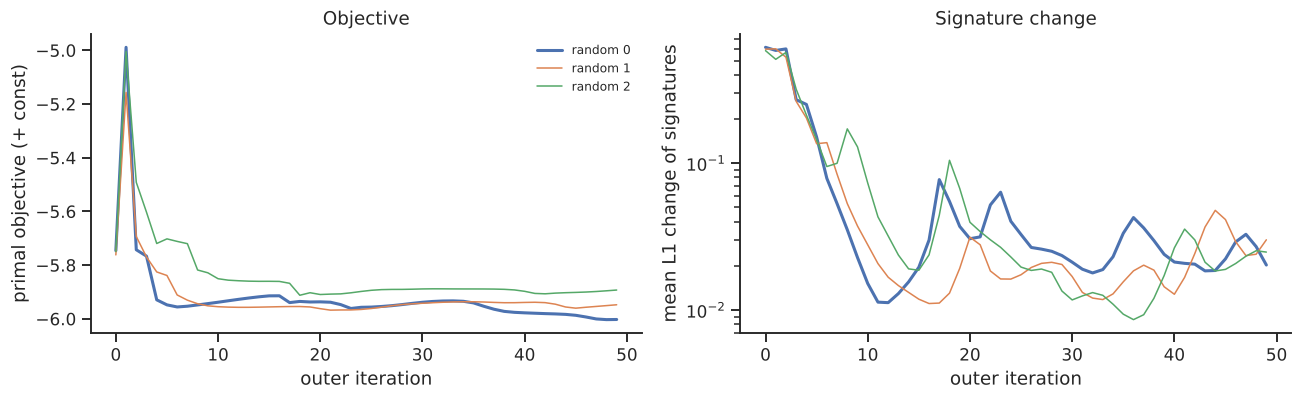

In [5]:
K_sig = W_true.shape[1]
t0 = time.time()
best, runs = fit(X, C, K_sig)
print(f"K={K_sig}, cost={DETAIL_COST}: {len(runs)} restarts in {time.time() - t0:.1f}s; best = {best['init']} "
      f"after {len(best['hist'])} outer iterations")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for d in runs:
    axes[0].plot(d["hist"].iter, d["hist"].objective, label=d["init"], lw=2 if d is best else 1)
    axes[1].plot(d["hist"].iter, d["hist"].change, label=d["init"], lw=2 if d is best else 1)
axes[0].set(xlabel="outer iteration", ylabel="primal objective (+ const)", title="Objective")
axes[1].set(xlabel="outer iteration", ylabel="mean L1 change of signatures", yscale="log", title="Signature change")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

totals = X.sum().values
m = match(best["W"], W_true)
W_est = pd.DataFrame(best["W"][:, m.est_col], index=CHANNELS, columns=m.true)
H_est = pd.DataFrame(best["H"][m.est_col] * totals, index=m.true, columns=X.columns)
m["exposure r"] = [np.corrcoef(H_est.loc[s], H_true.loc[s])[0, 1] for s in m.true]
print(f"mean cosine {m.cosine.mean():.3f}; recovered (cos ≥ {COS_GOOD}): {(m.cosine >= COS_GOOD).sum()}/{K_sig}")
m.sort_values("cosine").drop(columns="est_col").round(3)

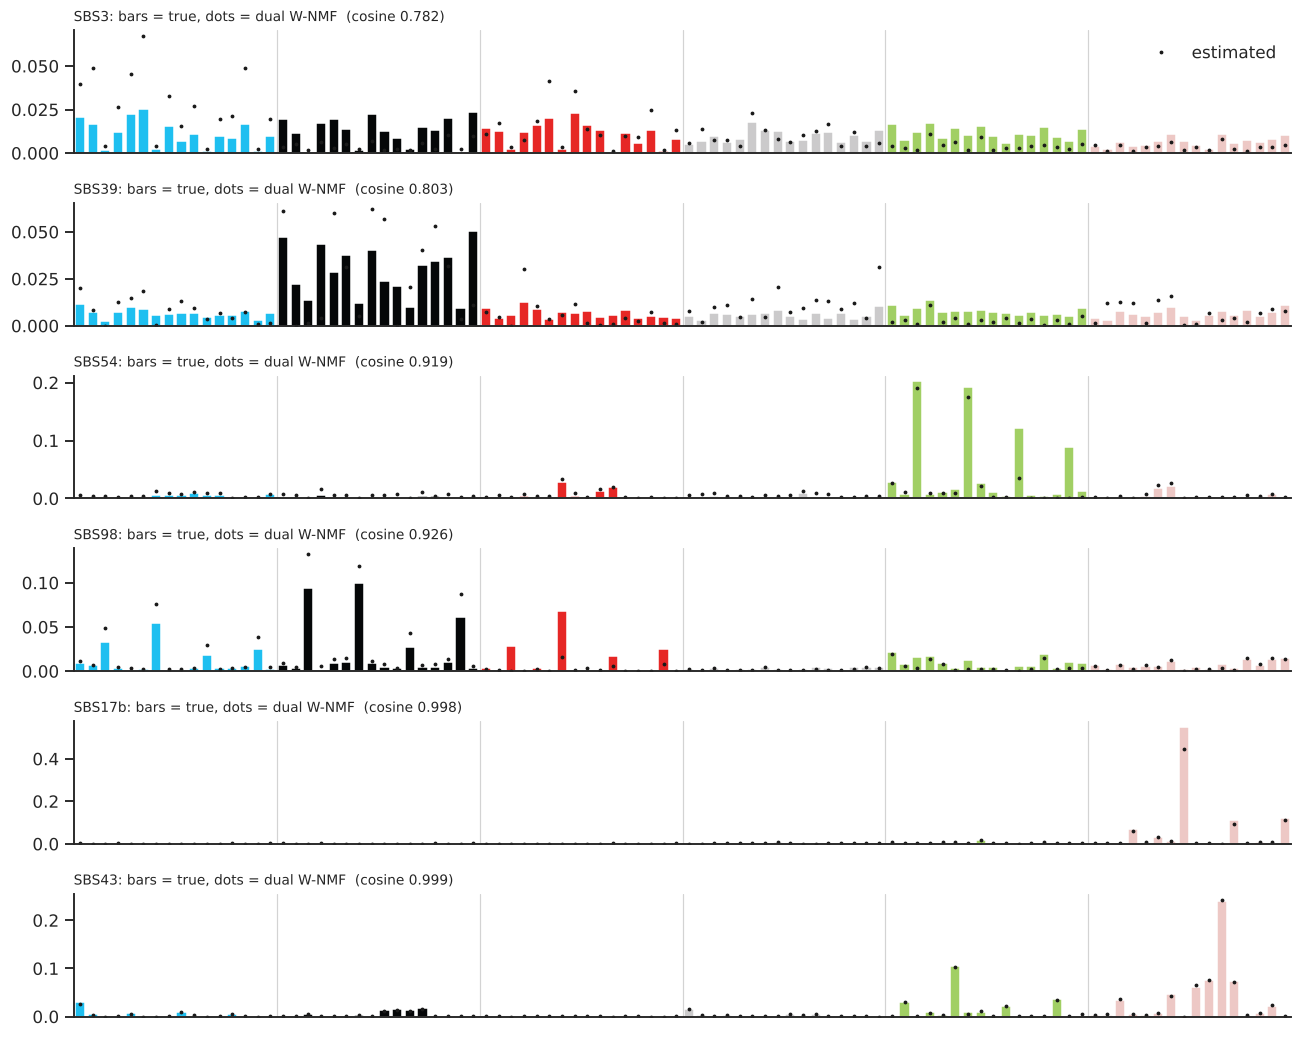

In [6]:
order = m.sort_values("cosine").true.tolist()
show = order[:4] + order[-2:]
fig, axes = plt.subplots(len(show), 1, figsize=(12, 1.6 * len(show)), sharex=True)
x = np.arange(96)
for ax, s in zip(axes, show):
    ax.bar(x, W_true[s], color=[SUB_COLORS[c] for c in SUB_OF], width=0.8)
    ax.plot(x, W_est[s], "k.", ms=3, label="estimated")
    for i in range(1, 6):
        ax.axvline(16 * i - 0.5, c="lightgrey", lw=0.8)
    ax.set_xticks([]); ax.set_xlim(-0.5, 95.5)
    ax.set_title(f"{s}: bars = true, dots = dual W-NMF  (cosine {m.set_index('true').at[s, 'cosine']:.3f})", fontsize=9, loc="left")
axes[0].legend(frameon=False, loc="upper right")
plt.tight_layout()

## 4. Sensitivity and a diagnostic

**Started at the truth.** If the true signatures were a minimiser of the objective, a fit started from them would stay there. The table shows how far it drifts, and whether the fitted signatures become sharper or blurrier (mean entropy) than the truth. A low-burden normalised sample is a spiky empirical histogram, and an OT loss treats it as an exact distribution, which pulls the signatures towards sharper profiles. The entropy barrier $\rho_2$ on $D$ pushes back towards higher entropy, which is why it matters so much here.

In [7]:
entropy = lambda M: float(-(M * np.log(M + 1e-300)).sum(0).mean())
rows = []
for rho2 in [0.01, 0.03, 0.05, 0.1]:
    for start in ["truth", "random"]:
        D0 = W_true.values if start == "truth" else None
        D, Lam, hist = dual_wnmf(X, C, K_sig, rho2=rho2, rng=SEED, D0=D0)
        mk = match(D, W_true)
        rows.append(dict(rho2=rho2, start=start, mean_cos=mk.cosine.mean(), recovered=(mk.cosine >= COS_GOOD).sum(),
                         entropy_est=entropy(D), entropy_true=entropy(W_true.values)))
for how in ["uniform", "sqrt"]:
    D, Lam, hist = dual_wnmf(X, C, K_sig, weights=how, rng=SEED)
    mk = match(D, W_true)
    rows.append(dict(rho2=RHO2, start=f"random, weights={how}", mean_cos=mk.cosine.mean(), recovered=(mk.cosine >= COS_GOOD).sum(),
                     entropy_est=entropy(D), entropy_true=entropy(W_true.values)))
pd.DataFrame(rows).round(3)

,rho2,start,mean_cos,recovered,entropy_est,entropy_true
0,0.01,truth,0.915,11,2.683,3.427
1,0.01,random,0.909,9,2.764,3.427
2,0.03,truth,0.959,14,3.050,3.427
3,0.03,random,0.867,11,3.168,3.427
4,0.05,truth,0.970,14,3.253,3.427
5,0.05,random,0.950,13,3.371,3.427
6,0.10,truth,0.979,15,3.532,3.427
7,0.10,random,0.888,11,3.707,3.427
8,0.05,"random, weights=uniform",0.828,9,3.331,3.427
9,0.05,"random, weights=sqrt",0.876,10,3.443,3.427


## 5. Benchmark over the 9 simulated conditions

In [8]:
bench, fits = [], {}
t0 = time.time()
for cost in BENCH_COSTS:
    Cc = load_cost(cost)
    for k in N_SIGNATURES_LIST:
        for noise in NOISE_LEVELS:
            Xk, Wk, Hk = load(k, noise)
            b, _ = fit(Xk, Cc, k)
            mk = match(b["W"], Wk)
            He = b["H"][mk.est_col] * Xk.sum().values
            fits[(cost, k, noise)] = (b, mk, He)
            bench.append(dict(cost=cost, k=k, noise=noise, mean_cos=mk.cosine.mean(), min_cos=mk.cosine.min(),
                              recovered=f"{(mk.cosine >= COS_GOOD).sum()}/{k}",
                              exposure_r=np.mean([np.corrcoef(He[i], Hk.loc[s])[0, 1] for i, s in enumerate(mk.true)]),
                              best_init=b["init"], outer_iters=len(b["hist"])))
        print(f"{cost}: K={k} done after {time.time() - t0:.0f}s")
bench = pd.DataFrame(bench)
bench.round(3)

lin_hamming: K=8 done after 122s


lin_hamming: K=15 done after 253s


lin_hamming: K=25 done after 385s


graph_struct: K=8 done after 506s


graph_struct: K=15 done after 629s


graph_struct: K=25 done after 764s


,cost,k,noise,mean_cos,min_cos,recovered,exposure_r,best_init,outer_iters
0,lin_hamming,8,0.02,0.986,0.937,8/8,0.988,random 0,50
1,lin_hamming,8,0.04,0.976,0.875,7/8,0.986,random 0,50
2,lin_hamming,8,0.06,0.980,0.894,7/8,0.989,random 2,50
3,lin_hamming,15,0.02,0.926,0.543,12/15,0.935,random 1,50
4,lin_hamming,15,0.04,0.933,0.647,12/15,0.944,random 2,50
5,lin_hamming,15,0.06,0.916,0.409,13/15,0.916,random 1,50
6,lin_hamming,25,0.02,0.818,0.201,12/25,0.691,random 0,50
7,lin_hamming,25,0.04,0.854,0.434,12/25,0.763,random 0,50
8,lin_hamming,25,0.06,0.819,0.345,11/25,0.734,random 2,50
9,graph_struct,8,0.02,0.976,0.912,8/8,0.981,random 0,50


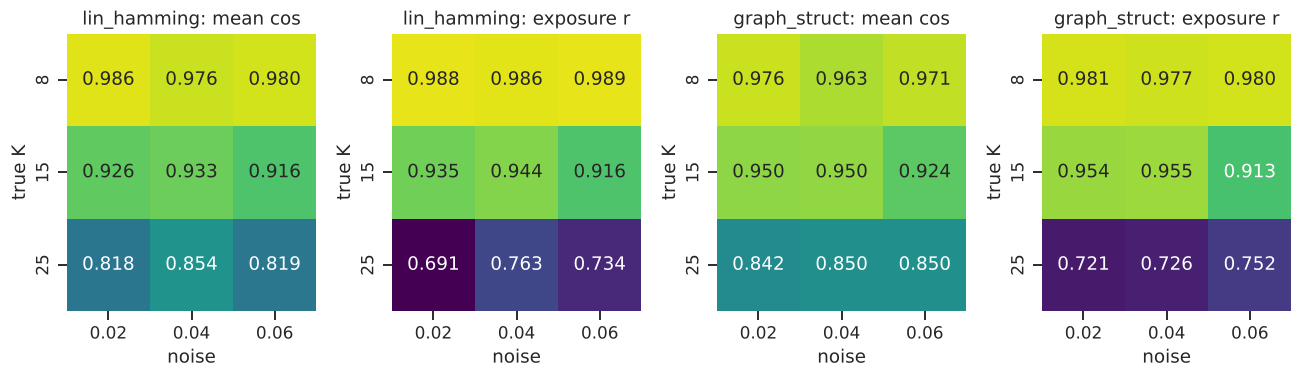

In [9]:
fig, axes = plt.subplots(1, 2 * len(BENCH_COSTS), figsize=(6 * len(BENCH_COSTS), 3.6), squeeze=False)
for i, cost in enumerate(BENCH_COSTS):
    b = bench[bench.cost == cost]
    for j, metric in enumerate(["mean_cos", "exposure_r"]):
        ax = axes[0, 2 * i + j]
        sns.heatmap(b.pivot(index="k", columns="noise", values=metric), ax=ax, annot=True, fmt=".3f",
                    cmap="viridis", vmin=0.7, vmax=1, cbar=False)
        ax.set(title=f"{cost}: {metric.replace('_', ' ')}", xlabel="noise", ylabel="true K")
plt.tight_layout()

## 6. Save

`results/wnmf_dual/<cost>/` with the same file layout as `06`, so `07` picks the results up automatically.

In [10]:
for (cost, k, noise), (b, mk, He) in fits.items():
    d = OUT / cost
    d.mkdir(exist_ok=True)
    t = tag(k, noise)
    pd.DataFrame(b["W"][:, mk.est_col], index=CHANNELS, columns=mk.true).to_csv(d / f"W_{t}.csv")
    pd.DataFrame(He, index=mk.true, columns=load(k, noise)[0].columns).to_csv(d / f"H_{t}.csv")
    mk.to_csv(d / f"match_{t}.csv", index=False)
bench.to_csv(OUT / "benchmark.csv", index=False)
(OUT / "params.json").write_text(json.dumps(dict(GAMMA=GAMMA, RHO1=RHO1, RHO2=RHO2, N_OUTER=N_OUTER, N_INNER=N_INNER,
                                                 OUTER_TOL=OUTER_TOL, SAMPLE_WEIGHT=SAMPLE_WEIGHT, N_RESTARTS=N_RESTARTS,
                                                 SEED=SEED, BENCH_COSTS=BENCH_COSTS), indent=2))
sorted(str(p.relative_to(OUT)) for p in OUT.rglob("*.csv"))[:6]

['benchmark.csv',
 'graph_struct/H_k15_noise2pct.csv',
 'graph_struct/H_k15_noise4pct.csv',
 'graph_struct/H_k15_noise6pct.csv',
 'graph_struct/H_k25_noise2pct.csv',
 'graph_struct/H_k25_noise4pct.csv']